# Total Perspective Vortex
## Treatment
---
Now that we've cleaned our data let's see what it looks like.

In [1]:
import mne
import pathlib as pth
import matplotlib.pyplot as plt

In [2]:
PASSBAND_LOW    = 8
PASSBAND_HIGH   = 30

In [3]:
data_folder = pth.Path('../eeg-motor-movementimagery-dataset-1.0.0/files')

s001 = data_folder / 'S001'

%matplotlib qt
s001r03 = s001 / 'S001R03.edf'
raw = mne.io.read_raw_edf(s001r03)
data = raw.load_data()
data.plot()

data_cpy = data.copy()
data_cpy.filter(PASSBAND_LOW, PASSBAND_HIGH, verbose=False)

data_cpy.plot()

plt.show()

Extracting EDF parameters from ../eeg-motor-movementimagery-dataset-1.0.0/files/S001/S001R03.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 19999  =      0.000 ...   124.994 secs...
Using matplotlib as 2D backend.


With theses plots, we can see that the signal have **less noise**, after the filter.

Now, we can try to pass the signal through a **Spatial Filter** and check what the values look like.
Thanks to [this papper](https://doc.ml.tu-berlin.de/bbci/publications/BlaTomLemKawMue08.pdf), we have this **comparison** of graphs that illustrate the filtering of different **spatial filter**.

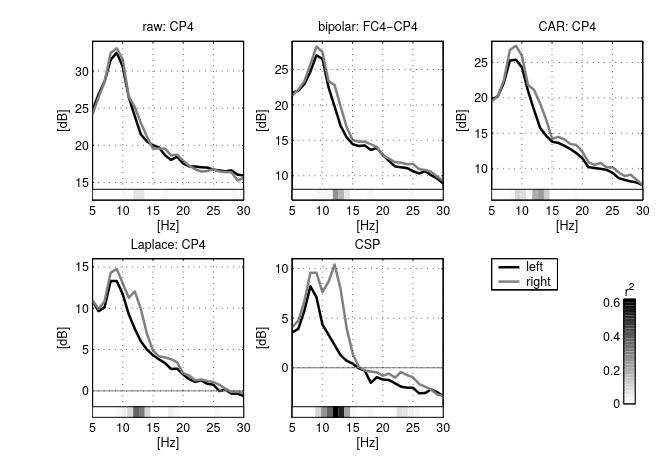

We can see that there's two graphs that really differentiate between **right** and **left**: CSP and Laplace.
This information is validated by this, previously referenced, [github repo](https://github.com/RezaSaadatyar/Motor-imagery-based-EEG-signal-processing), which use **both of them**.

Since the most commonly used is the **CSP**, for **Common Spatial Pattern**, we'll start by this.

Used Annotations descriptions: [np.str_('T0'), np.str_('T1'), np.str_('T2')]
Computing rank from data with rank=None
    Using tolerance 0.00047 (2.2e-16 eps * 64 dim * 3.3e+10  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=2 covariance using EMPIRICAL
Done.
Estimating class=3 covariance using EMPIRICAL
Done.


/tmp/ipykernel_645686/1786306070.py:27: RuntimeWarning: More than 25 topomaps plots requested. This might take a while.
  fig_pattern = mne.decoding.get_spatial_filter_from_estimator(csp, epochs.info).plot_patterns(ch_type='eeg', extrapolate='local')


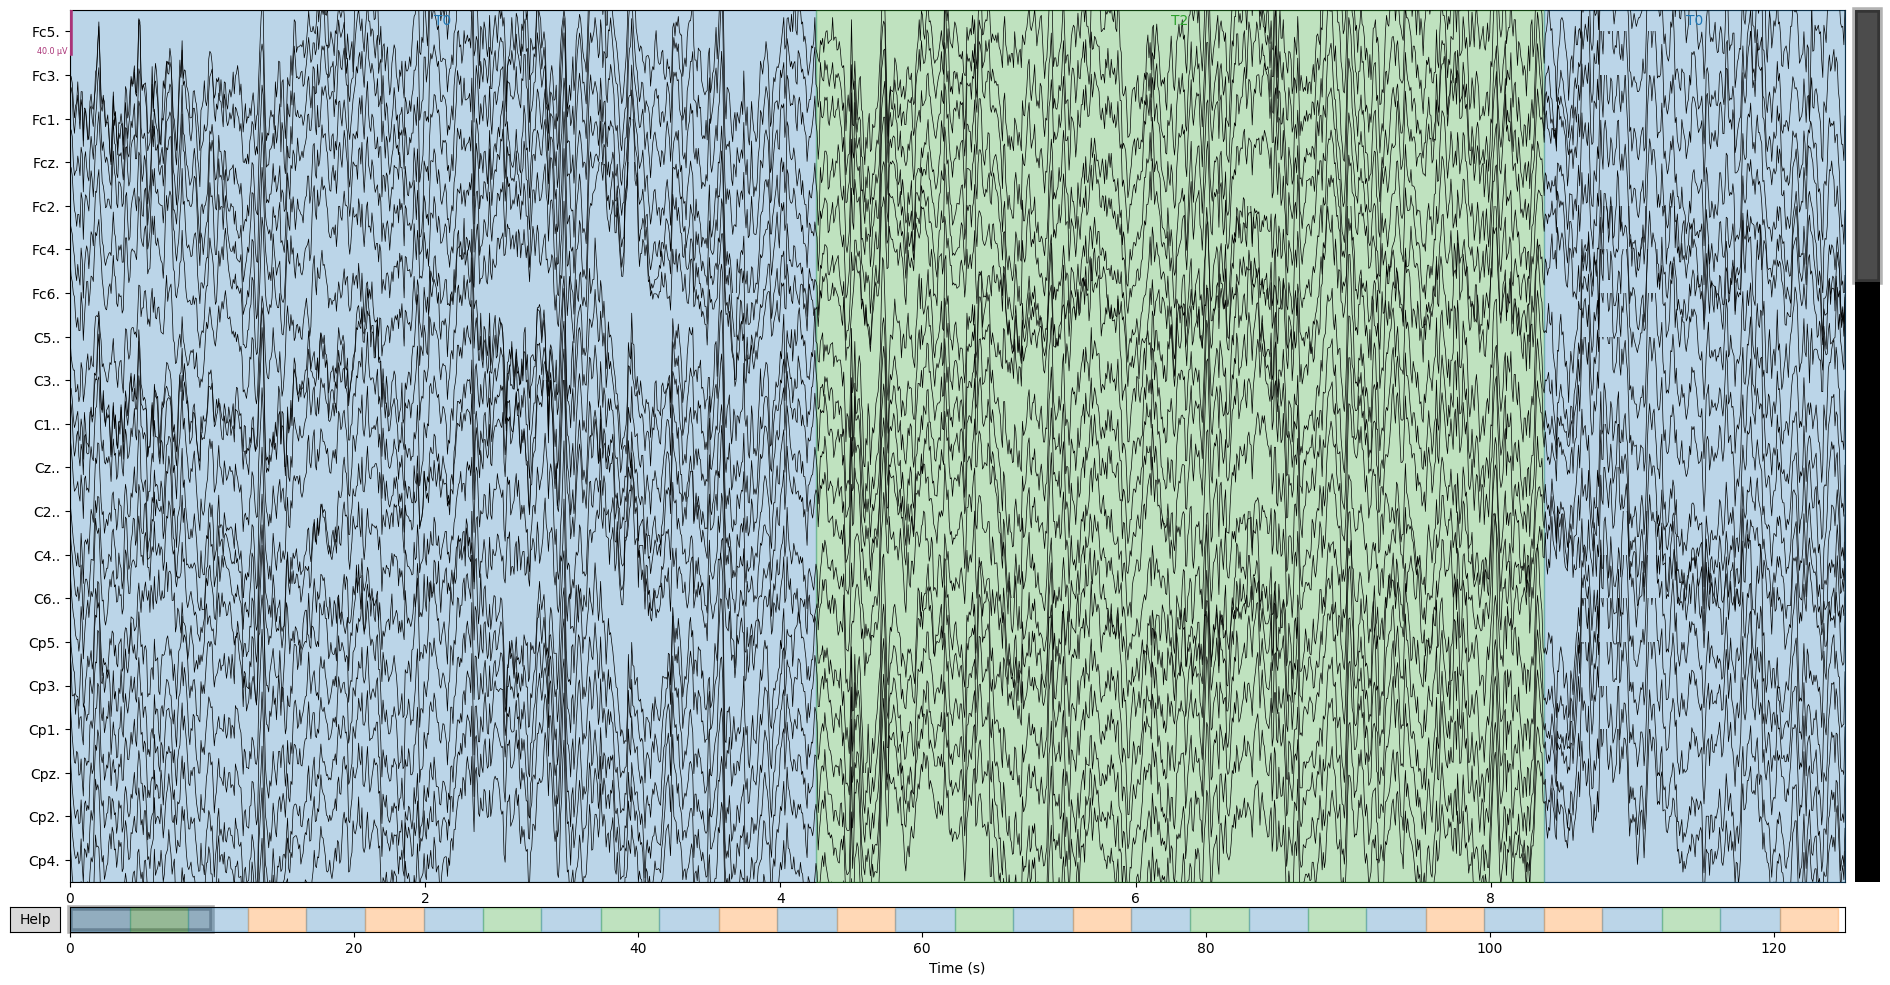

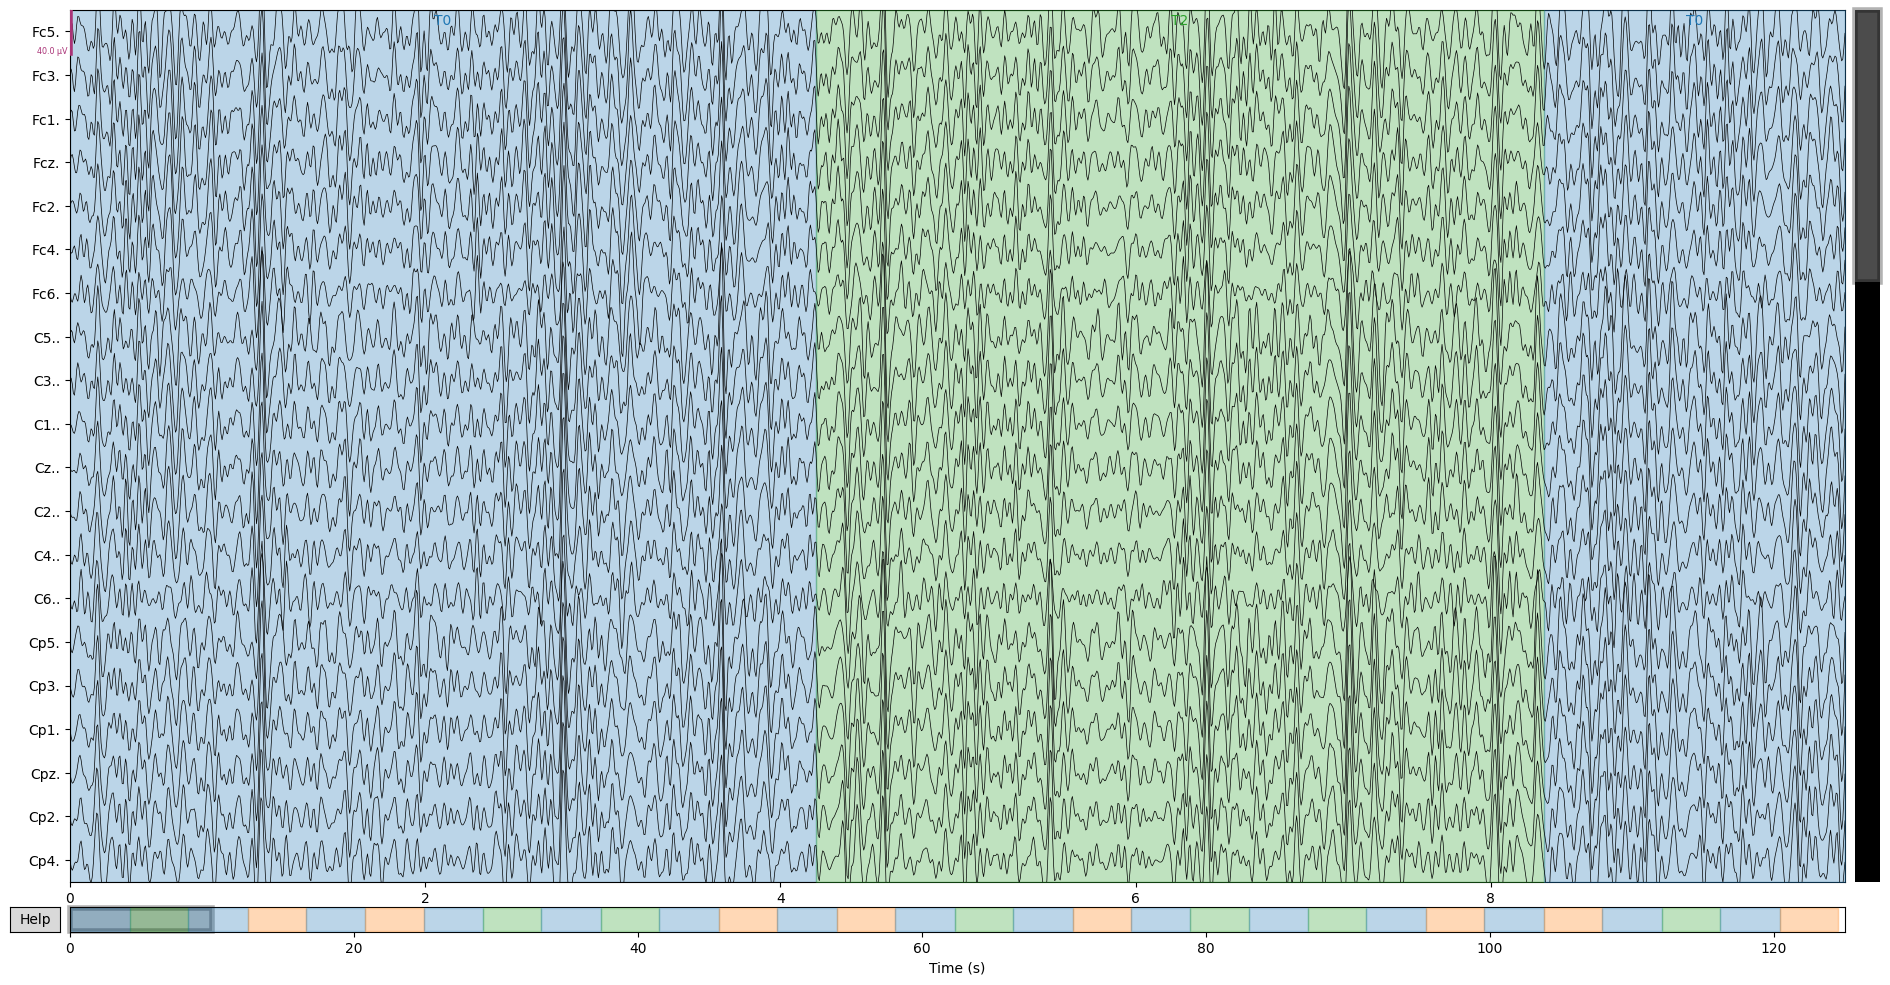

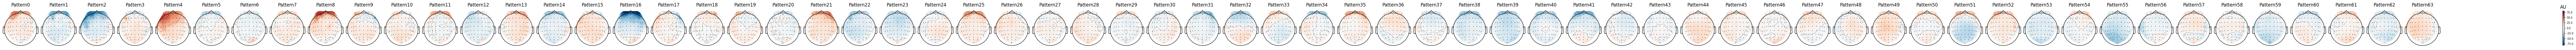

Channels marked as bad:
none
Channels marked as bad:
none


In [4]:
ch_names = raw.ch_names
ch_names = {name: name.rstrip('.') for name in ch_names}
sfreq = 160
montage = mne.channels.make_standard_montage('standard_1005')
raw.rename_channels(lambda name: name.rstrip('.'))
raw.set_montage(montage, on_missing='ignore', match_case=False)

events, events_id = mne.events_from_annotations(raw)

# CSP doesn't really work for multi class, that's why we'll only use the two most important part (T1 and T2)

events_id = {
    'T1': events_id['T1'],
    'T2': events_id['T2'],
}

epochs = mne.Epochs(raw, events, events_id, tmin=0.5, tmax=3, baseline=None, preload=True, verbose=False)

X_extract = epochs.get_data(copy=True)
y_extract = epochs.events[:, -1]

csp = mne.decoding.CSP(n_components=4, reg=None, log=True, norm_trace=False)

csp.fit(X_extract, y_extract)

%matplotlib inline
fig_pattern = mne.decoding.get_spatial_filter_from_estimator(csp, epochs.info).plot_patterns(ch_type='eeg', extrapolate='local')
plt.show()

NOTE: plot_filters() is a legacy function. New code should use get_spatial_filter_from_estimator(clf, info=info).plot_filters().


/tmp/ipykernel_645686/2379026169.py:2: RuntimeWarning: More than 25 topomaps plots requested. This might take a while.
  fig_filters = csp.plot_filters(epochs.info, ch_type='eeg')


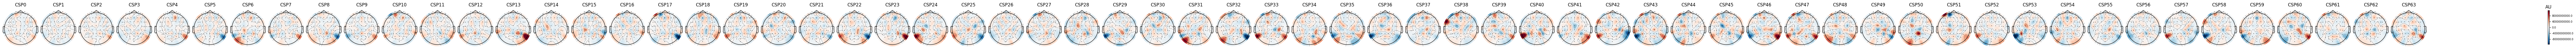

In [5]:
%matplotlib inline
fig_filters = csp.plot_filters(epochs.info, ch_type='eeg')
plt.show()

Those plots show us the different **patterns** found by **CSP** for each of the 64 electrodes.

There are electrodes that carry more information than the others.

And by printing the shape of the **CSP transformed** data set...

In [6]:
print(f"Extracted data shape: {X_extract.shape}")
print(f"CSP Transformed data shape: {csp.transform(X_extract).shape}")

Extracted data shape: (15, 64, 401)
CSP Transformed data shape: (15, 4)


We can see that, compared to the **extracted data**, we have a lot less information !

It's with those newly transformed data that we'll train ou model !

But how does **CSP** work, and what does it return ?

### What does it return ?
**CSP** is a **Spatial Filter**, so it lessen the dimension of our data (X_extracted above).
It's goal is to find which information, in our case the electrodes, are the most meaningful, by extracting the one with the more and the less variance for each label.

For our case, it's like this:
- T1 (Right Fist / Both Fists)
    - Which electrodes with the more variance ?
    - Which electrodes with the less variance ?
- T2 (Left Fist / Both Feets)
    - Which electrodes with the more variance ?
    - Which electrodes with the less variance ?

Since theses information are different (Moving the right fist will increase the frequency of an electrode and decrease on the other), by obtaining theses information we'll also get a value, which correspond to the variance, and tell us immediately which type of movement it is.

The variance, in our case, will represent the "height" of the signal waves, which mean that a bigger variance means a larger wave.

Let's imagine that, thanks to the CSP, we obtained two channels.
So we have something like this:

- T1 (Right Fist / Both Fists)
    - Channel 1: [+60, -56, +58, -50, +62, -48, ...] => Var = ~118
    - Channel 2: [+2, -3, +4, -2, +5 -2, ...] => Var = ~8

- T2 (Left Fist / Both Feets)
    - Channel 1: [+2, -3, +4, -2, +5 -2, ...] => Var = ~8
    - Channel 2: [+60, -56, +58, -50, +62, -48, ...] => Var = ~118

It means that, with the two channels, we can immediately differentiate if it's a T1 or a T2 with the variance.

We can select the number of channels we want, it can be more than two, and CSP will select the best X channels for our case.

### How does it work ?
For it training, CSP need both **X** (the dataset) and **y** (it's label).

**CSP** will, first, calculate the **covariance** of each channels, it means the way the electrodes change one another along time.

With this, we'll obtain which channel work the same way as the other.

For exemple:
| Channels  | t0 | t1 | t2 | t3 | t4 | t5 |
|-----------|----|----|----|----|----|----|
| Channel 1 | 1  | 3  | 1  | 3  | 1  | 3  |
| Channel 2 | 1  | 2  | 3  | 1  | 2  | 3  |
| Channel 3 | 1  | -3 | 1  | -3 | 1  | -3 |
| Channel 4 | 1  | 10 | 20 | 1  | 10 | 20 |

In this table, we can see that when channel 1 increase, channel 3 decrease at the same time.
On the other hand, the channel 2 and 4, both increase at the same time.

It means that, over time, 1-3, and 2-4 have the same behavior.

After that, we'll check which combination of channels maximize the variance for each class.
For exemple, channel 1 and 3 maximize the variance for T1, and 2 and 4 maximize the variance for T2.

After computing this, CSP will apply a **weight** over each channels to make them more or less important.

Like explained above, **CSP** will not return all the channels (it wouldn't be a **spatial filter** otherwise), but only the x channels with the more meaning, and only the **log of the proportion of the total variance**.

That why we pass from a shape of **(15, 64, 401)** to a shape of **(15, 4)**.

The **15** is the **number of epochs**, **64** the **number of electrodes**, and **401** is the **number of time point** in our first case, and in the seconde, **15** is the number of epochs and **4** is the **log of the probability** explained earlier.